# CS 521 HW4, Problem 3: PPO on CartPole

Open this notebook in Google Colab. The CPU runtime is sufficient: a GPU does not make this notebook faster.

The notebook has a complete implementation of PPO for the CartPole-v1 environment.
In part (a) of Problem 3, you run it and examine two of its parts.
In Bonus Research Question 2, you change the algorithm to improve learning.
Do not change the environment, the training budget (`total_steps`) or the evaluation.

**Environment.** CartPole-v1 gives a reward of +1 for each step. An episode ends when the pole falls
(*termination*) or after 500 steps (*truncation*, a time limit). Thus the maximum return is 500.

In [2]:
# !pip install gymnasium   # Colab has gymnasium. Remove the comment if the import fails.
import copy
import time

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Categorical

torch.set_num_threads(1)

CONFIG = dict(
    total_steps=200_000,   # training budget (environment steps). Do not change.
    num_envs=4,            # parallel environments
    num_steps=128,         # steps per environment for each rollout
    lr=2.5e-4,
    anneal_lr=True,        # decrease the learning rate linearly to 0
    gamma=0.99,
    gae_lambda=0.95,
    num_minibatches=4,
    update_epochs=4,
    clip_coef=0.2,
    ent_coef=0.01,
    vf_coef=0.5,
    max_grad_norm=0.5,
    norm_adv=True,         # normalize the advantages in each minibatch
)
SEEDS = [0, 1, 2, 3, 4]

# Environments

`Envs` runs `num_envs` copies of CartPole. When an episode ends, `step` resets that copy automatically.
For each copy, `step` returns:

* `obs`: the next observation. If the episode ended, this is the first observation of the new episode.
* `reward`, `terminated`, `truncated`.
* `final_obs`: the last observation of the episode that ended (`None` if the episode did not end).

`step` also records the return of each finished episode in `self.episodes` as `(global_step, return)`.

In [3]:
class Envs:
    def __init__(self, n, seed):
        self.envs = [gym.make("CartPole-v1") for _ in range(n)]
        self.obs = np.stack([e.reset(seed=seed + i)[0] for i, e in enumerate(self.envs)])
        for i, e in enumerate(self.envs):
            e.action_space.seed(seed + i)
        self.ep_return = np.zeros(n)
        self.global_step = 0
        self.episodes = []

    def step(self, actions):
        rewards, terms, truncs, final_obs = [], [], [], []
        for i, (e, a) in enumerate(zip(self.envs, actions)):
            o, r, term, trunc, _ = e.step(int(a))
            self.ep_return[i] += r
            fo = None
            if term or trunc:
                fo = o
                self.episodes.append((self.global_step + i + 1, self.ep_return[i]))
                self.ep_return[i] = 0
                o, _ = e.reset()
            self.obs[i] = o
            rewards.append(r); terms.append(term); truncs.append(trunc); final_obs.append(fo)
        self.global_step += len(self.envs)
        return self.obs.copy(), np.array(rewards), np.array(terms), np.array(truncs), final_obs

# Agent

The agent has two separate networks with 2 hidden layers of 64 neurons: the actor (policy) and the critic (value).

In [4]:
def layer_init(layer, std=np.sqrt(2), bias=0.0):
    nn.init.orthogonal_(layer.weight, std)
    nn.init.constant_(layer.bias, bias)
    return layer


class Agent(nn.Module):
    def __init__(self, obs_dim=4, n_actions=2):
        super().__init__()
        self.critic = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 1), std=1.0))
        self.actor = nn.Sequential(
            layer_init(nn.Linear(obs_dim, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, 64)), nn.Tanh(),
            layer_init(nn.Linear(64, n_actions), std=0.01))

    def get_value(self, x):
        return self.critic(x).squeeze(-1)

    def get_action_and_value(self, x, action=None):
        dist = Categorical(logits=self.actor(x))
        if action is None:
            action = dist.sample()
        return action, dist.log_prob(action), dist.entropy(), self.get_value(x)

# PPO

`compute_gae` calculates the advantages with generalized advantage estimation (GAE).
`ppo_update` does `update_epochs` passes over the rollout with the clipped surrogate objective.
`train_ppo(seed, cfg)` trains one agent and returns the agent and the list of `(global_step, return)` of the
training episodes.

In [5]:
def compute_gae(rewards, values, dones, next_value, next_done, gamma, lam):
    # rewards, values, dones: (num_steps, num_envs). dones[t] = 1 if the episode ended at step t - 1,
    # thus obs[t] is the first observation of a new episode.
    T = len(rewards)
    adv = torch.zeros_like(rewards)
    last = 0
    for t in reversed(range(T)):
        not_done = 1.0 - (next_done if t == T - 1 else dones[t + 1])
        nv = next_value if t == T - 1 else values[t + 1]
        delta = rewards[t] + gamma * nv * not_done - values[t]
        last = delta + gamma * lam * not_done * last
        adv[t] = last
    return adv, adv + values


def ppo_update(agent, opt, b, cfg):
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    stats = []
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            ratio = (logp - b["logp"][mb]).exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = torch.max(-adv * ratio,
                                -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            opt.step()
            stats.append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
    return {"clip_frac": float(np.mean(stats))}


def train_ppo(seed, cfg=None, verbose=False):
    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4); actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N); rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v
            o, r, term, trunc, _ = envs.step(a.numpy())
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        stats = ppo_update(agent, opt, b, cfg)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  "
                  f"clip frac {stats['clip_frac']:.3f}")
    return agent, envs.episodes, time.time() - start

# Evaluation

`evaluate_policy` runs the greedy policy (the action with the highest probability) for 20 episodes with fixed seeds.
`summarize(runs)` gives these metrics for a list of runs (one run for each seed):

* `auc`: the mean of the learning curve over the training budget. The learning curve is the mean return of the last
  10 training episodes, at 100 equally spaced steps. A higher value means faster learning.
* `steps_to_475`: the first step where the mean return of the last 10 training episodes is at least 475.
  If a run does not get there, we use `total_steps`.
* `final`: the return of the greedy policy at the end of training.

`plot_curves` plots the mean learning curve over the seeds. Use these functions for all the numbers in your report.

In [6]:
@torch.no_grad()
def evaluate_policy(agent, episodes=20, seed=10_000):
    env = gym.make("CartPole-v1")
    total = 0.0
    for k in range(episodes):
        o, _ = env.reset(seed=seed + k)
        done = False
        while not done:
            a = agent.actor(torch.tensor(o, dtype=torch.float32)).argmax().item()
            o, r, term, trunc, _ = env.step(a)
            total += r
            done = term or trunc
    return total / episodes


def learning_curve(episodes, total_steps=CONFIG["total_steps"], points=100, window=10):
    steps = np.array([s for s, _ in episodes])
    rets = np.array([r for _, r in episodes])
    grid = np.linspace(total_steps / points, total_steps, points)
    curve = []
    for g in grid:
        r = rets[steps <= g][-window:]
        curve.append(r.mean() if len(r) else 0.0)
    return grid, np.array(curve)


def steps_to(episodes, target=475, window=10, total_steps=CONFIG["total_steps"]):
    rets = [r for _, r in episodes]
    for k in range(window, len(episodes) + 1):
        if np.mean(rets[k - window:k]) >= target:
            return episodes[k - 1][0]
    return total_steps


def run_seeds(cfg=None, seeds=SEEDS, train_fn=None, verbose=True):
    train_fn = train_fn or train_ppo
    runs = []
    for s in seeds:
        agent, episodes, sec = train_fn(s, cfg)
        runs.append({"seed": s, "episodes": episodes, "time": sec, "final": evaluate_policy(agent)})
        if verbose:
            print(f"seed {s}: auc {learning_curve(episodes)[1].mean():6.1f}  steps_to_475 {steps_to(episodes):6d}  "
                  f"final {runs[-1]['final']:6.1f}  time {sec:5.1f} s")
    return runs


def summarize(runs, name=""):
    auc = [learning_curve(r["episodes"])[1].mean() for r in runs]
    st = [steps_to(r["episodes"]) for r in runs]
    fin = [r["final"] for r in runs]
    res = {"name": name, "auc": np.mean(auc), "auc_std": np.std(auc), "steps_to_475": np.mean(st),
           "solved": sum(s < CONFIG["total_steps"] for s in st), "final": np.mean(fin),
           "final_std": np.std(fin), "time": np.mean([r["time"] for r in runs])}
    print(f"{name:<24} auc {res['auc']:6.1f} +- {res['auc_std']:5.1f}  steps_to_475 {res['steps_to_475']:8.0f} "
          f"({res['solved']}/{len(runs)} runs)  final {res['final']:6.1f} +- {res['final_std']:5.1f}  "
          f"time {res['time']:5.1f} s")
    return res


def plot_curves(named_runs):
    import matplotlib.pyplot as plt
    for name, runs in named_runs.items():
        curves = np.stack([learning_curve(r["episodes"])[1] for r in runs])
        grid = learning_curve(runs[0]["episodes"])[0]
        m, s = curves.mean(0), curves.std(0)
        plt.plot(grid, m, label=name)
        plt.fill_between(grid, m - s, m + s, alpha=0.2)
    plt.xlabel("environment steps"); plt.ylabel("mean return (last 10 episodes)"); plt.legend(); plt.show()

# (a) Run PPO

Train PPO with the default configuration for the 5 seeds. Then train two changed versions:

* Without clipping: `{"clip_coef": 1e9}`.
* Without GAE (Monte Carlo advantages): `{"gae_lambda": 1.0}`.

seed 0: auc  275.3  steps_to_475  75391  final  275.9  time  40.5 s
seed 1: auc  373.9  steps_to_475  69272  final  500.0  time  40.0 s
seed 2: auc  313.1  steps_to_475  76158  final  391.1  time  41.2 s
seed 3: auc  356.8  steps_to_475 113158  final  500.0  time  46.1 s
seed 4: auc  388.9  steps_to_475  55124  final  500.0  time  42.0 s
seed 0: auc  386.8  steps_to_475  75710  final  500.0  time  42.0 s
seed 1: auc  316.9  steps_to_475 140714  final  500.0  time  43.0 s
seed 2: auc  390.9  steps_to_475  82375  final  500.0  time  43.2 s
seed 3: auc  281.1  steps_to_475  87922  final  388.0  time  42.6 s
seed 4: auc  320.0  steps_to_475  72421  final  494.9  time  42.3 s
seed 0: auc  265.9  steps_to_475 200000  final  493.1  time  42.1 s
seed 1: auc  327.4  steps_to_475 130080  final  500.0  time  42.2 s
seed 2: auc  322.5  steps_to_475 130741  final  500.0  time  42.4 s
seed 3: auc  347.0  steps_to_475 118884  final  500.0  time  42.3 s
seed 4: auc  362.9  steps_to_475 130792  final  

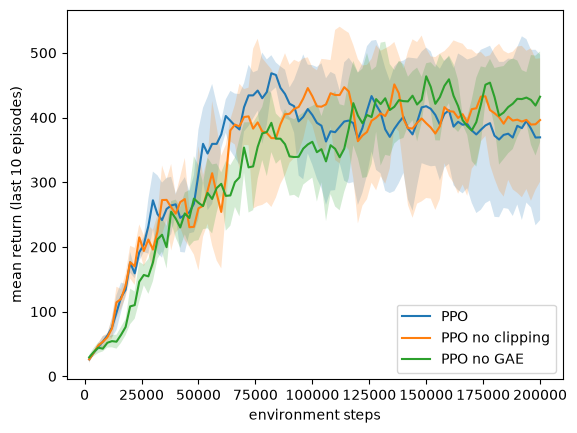

In [9]:
all_runs = {"PPO": run_seeds()}
# TODO: train the two changed versions
all_runs["PPO no clipping"] = run_seeds({"clip_coef": 1e9})
all_runs["PPO no GAE"] = run_seeds({"gae_lambda": 1.0})
results = {name: summarize(runs, name) for name, runs in all_runs.items()}
plot_curves(all_runs)

**Results of (a).** I trained each version with 5 seeds (0 to 4) and 200,000 environment steps, using `run_seeds`, `summarize` and the learning curves. The numbers are mean ± std over the 5 seeds.

| Version | auc | steps_to_475 | runs that reach 475 | final (greedy) |
|---|---|---|---|---|
| PPO (default) | 341.6 +- 41.8 | 77,821 | 5/5 | 433.4 +- 89.3 |
| No clipping (`clip_coef=1e9`) | 339.2 +- 42.8 | 91,828 | 5/5 | 476.6 +- 44.3 |
| No GAE (`gae_lambda=1.0`) | 325.1 +- 32.9 | 142,099 | 4/5 | 498.6 +- 2.8 |

**Analysis:**

**(i) How does clipping change learning,** Removing the clipping hardly changes the auc (339 vs 342), so the speed of learning in the first part of training is almost the same. It reaches 475 a bit later on average (92k vs 78k steps), but the seeds vary a lot (from 72k to 141k), so difference isn't reliable. The greedy final return is higher without clipping (477 vs 433), but the std is large for both, so it's similar as differences. In my runs, clipping did not matter much. I think is that the clipping only works when the probability ratio leaves [0.8, 1.2]. The learning rate is small (2.5e-4, goes down to 0) and each rollout is used for only 4 epochs, so the new stays close to the old one and the ratio is not clipped much, which is a safety limit on how far one update can move the policy, and it is not needed when the steps are already small. 

**(ii) How does GAE change learning,** Without GAE (`gae_lambda=1.0`) PPO is much slower to get to 475: 142k steps against 78k, and one seed (seed 0) never reaches it. The auc is also lower (325 vs 342). With lambda = 1 the advantage is the full Monte Carlo return minus the value, that is the sum of all the rewards until the end of the rollout (up to 128 steps) or the end of the episode. This estimate is unbiased, since it does not trust the critic, but its variance is high, because it adds the randomness of many future actions and states. A noisy advantage gives a noisy policy gradient, and the policy learns more slowly. With lambda = 0.95, GAE mixes the n-step returns, and it gives more weight to the near future and to the critic's value for the later steps. The critic is not perfect, so this adds some bias, but the variance gets much smaller. For CartPole, where every step has reward +1 and the episodes are long, this trade of a little bias for a lot less variance works better. I did not measure the bias or the variance directly, so this is the usual argument that fits the curves.

**(iii) Does PPO keep the maximum return after it gets there?,** No. In the default run, the learning curve often goes down after it first reaches 475. For seeds 0, 1 and 2 the curve falls back to about 190 to 205 after it first reached 475, and for seeds 3 and 4 it falls to about 337 and 311. Only seeds 3 and 4 end near 500 on the training curve (476 and 500), and the greedy final return is below 500 for seeds 0 and 2 (276 and 391). The same happens without clipping (seeds 3 and 4 fall to about 167 and 147). The no-GAE runs are more stable: after they first reach 475 they stay above about 366, and four of the five seeds end with a greedy return of 491 to 500. So there is a trade-off: no GAE is slower at the start but steadier at the end. I think the drops happen because PPO keeps updating the policy with noisy gradient steps even after it is already good, and one bad update with a stochastic policy can lose performance, since it has no mechanism to remember the best policy. Also, the `steps_to_475` metric only records the first time it reaches 475, so it hides these drops, and the greedy `final` return can differ from the training curve, because the training episodes use sampled actions.

# (b) Preference tuning and RL in LLMs

**Setup:** I compared the four public OLMo 2 1B checkpoints, using lm-evaluation-harness 0.4.13. I picked four benchmarks that measure different things:

- **IFEval** (instruction following, 0-shot),
- **GSM8K** (math reasoning, 5-shot),
- **TruthfulQA MC2** (truthfulness, 0-shot),
- **MMLU** (knowledge, 0-shot).

For every checkpoint, I used the same examples: the first 200 of IFEval, GSM8K and TruthfulQA, and the first 20 questions of each of the 57 MMLU subjects (1140 questions in total). Decoding was greedy with at most 512 new tokens, and the prompts and few-shot examples were the same for all models. The SFT, DPO and Instruct models used the chat template (with few-shot examples given as multi-turn chats for GSM8K). The base model has no chat template, so it got plain text. This means the base-vs-others comparison also changes the prompt format, which I keep in mind below.

I also computed two simple diversity numbers from the IFEval outputs: distinct-3 (the fraction of word 3-grams that are unique) and the fraction of outputs that contain a repeated 8-gram.

Goes through the four checkpoints one by one . For each checkpoint calls lm-evaluation-harness three times on the GPU, loading the model in ram from Hugging Face:

1. `ifeval` and `gsm8k`: the model generates an answer for the first 200 examples of each (greedy, at most 512 new tokens). IFEval answers are checked by rule-based checkers ("at least 300 words", "wrap the title in << >>"), and GSM8K answers are compared with the gold number.
2. `truthfulqa_mc2`: the model does not generate. It scores the likelihood of each true and false answer option for 200 questions, and the metric is the probability mass given to the true answers.
3. `mmlu`: also likelihood-based. It scores the four answer choices for the first 20 questions of each of the 57 subjects (1140 questions).

For SFT, DPO and Instruct the script adds `--apply_chat_template --fewshot_as_multiturn`, so the prompt is wrapped in the model's chat template. The base model gets plain text. The scores and every per-example sample are saved in `results/<model>/` (`--log_samples`), and the console output of each run is saved in a log file. After each checkpoint the script writes a line to `progress.txt` so I could see how far it was.

**Evaluation script:**

```bash
export HF_HUB_DISABLE_SYMLINKS_WARNING=1 PYTHONUTF8=1
PY=D:/conda/envs/521/python.exe
for M in OLMo-2-0425-1B OLMo-2-0425-1B-SFT OLMo-2-0425-1B-DPO OLMo-2-0425-1B-Instruct; do
  CHAT=""; [ "$M" != "OLMo-2-0425-1B" ] && CHAT="--apply_chat_template --fewshot_as_multiturn"
  MA="pretrained=allenai/$M,dtype=bfloat16"
  $PY -m lm_eval --model hf --model_args $MA --tasks ifeval,gsm8k --limit 200 --batch_size 16 --device cuda:0 --gen_kwargs max_gen_toks=512 $CHAT --output_path results/$M --log_samples > logs_$M.gen.txt 2>&1
  $PY -m lm_eval --model hf --model_args $MA --tasks truthfulqa_mc2 --limit 200 --batch_size 16 --device cuda:0 $CHAT --output_path results/$M --log_samples > logs_$M.tqa.txt 2>&1
  $PY -m lm_eval --model hf --model_args $MA --tasks mmlu --limit 20 --batch_size 16 --device cuda:0 $CHAT --output_path results/$M --log_samples > logs_$M.mmlu.txt 2>&1
  echo done $M >> progress.txt
done
```

**Table and diversity metrics:**

```python
import json, glob, re, collections, numpy as np
M = {"Base":"OLMo-2-0425-1B","SFT":"OLMo-2-0425-1B-SFT","DPO":"OLMo-2-0425-1B-DPO","Instruct":"OLMo-2-0425-1B-Instruct"}
def res(m):
    d = {}
    for f in glob.glob(f"results/{m}/*/results_*.json"):
        d.update(json.load(open(f))["results"])
    return d
rows = {}
for k, m in M.items():
    r = res(m); g = {}
    g["IFEval prompt-strict"] = r["ifeval"]["prompt_level_strict_acc,none"]
    g["IFEval inst-loose"] = r["ifeval"]["inst_level_loose_acc,none"]
    g["GSM8K flex"] = r["gsm8k"]["exact_match,flexible-extract"]
    g["GSM8K strict"] = r["gsm8k"]["exact_match,strict-match"]
    g["TruthfulQA MC2"] = r["truthfulqa_mc2"]["acc,none"]
    g["MMLU (1140 q)"] = r["mmlu"]["acc,none"]
    # diversity + length on IFEval outputs
    S = [json.loads(l) for l in open(glob.glob(f"results/{m}/*/samples_ifeval_*.jsonl")[0])]
    outs = [s["resps"][0][0] for s in S]
    toks = [o.split() for o in outs]
    g["IFEval mean words"] = np.mean([len(t) for t in toks])
    tri = [tuple(t[i:i+3]) for t in toks for i in range(len(t)-2)]
    g["distinct-3 (IFEval outs)"] = len(set(tri))/max(1,len(tri))
    g["self-rep (frac outs w/ repeated 8-gram)"] = np.mean([len(set(tuple(t[i:i+8]) for i in range(len(t)-7)))<max(1,len(t)-7)*0.8 for t in toks if len(t)>8])
    rows[k] = g
keys = list(rows["Base"])
print("| Metric | " + " | ".join(M) + " |"); print("|---|" + "---|"*4)
for k in keys: print(f"| {k} | " + " | ".join(f"{rows[m][k]:.3f}" if rows[m][k]<10 else f"{rows[m][k]:.0f}" for m in M) + " |")
json.dump(rows, open("eval_table.json","w"), indent=1)
# MMLU categories
print()
for k, m in M.items():
    r = res(m); print(k, {c: round(r[c]["acc,none"],3) for c in ["mmlu_stem","mmlu_humanities","mmlu_social_sciences","mmlu_other"] if c in r})
```

- **IFEval** (prompt-strict, instruction-loose): how well the model follows instructions that can be checked by rules.
- **GSM8K** (flexible, strict): math reasoning. Strict needs the answer in the exact `####` format, flexible takes the last number in the answer.
- **TruthfulQA MC2**: how much probability the model gives to true answers over common false beliefs.
- **MMLU**: general knowledge (the average over the 1140 questions).
- **Mean words per IFEval output**: how long the answers are.
- **distinct-3** and **outputs with repeated 8-grams**: a simple measure of diversity and repetition computed from the IFEval outputs. Distinct-3 is the fraction of word 3-grams that are unique, so a low value means the text repeats itself. The second number is the fraction of outputs where a lot of 8-grams are repeated, which catches looping text.

It also adds a MMLU score

**Example outputs:**

```python
import json, glob
M = {"Base":"OLMo-2-0425-1B","SFT":"OLMo-2-0425-1B-SFT","DPO":"OLMo-2-0425-1B-DPO","Instruct":"OLMo-2-0425-1B-Instruct"}
def load(m,t): return [json.loads(l) for l in open(glob.glob(f"results/{m}/*/samples_{t}_*.jsonl")[0])]
for t, idx in [("ifeval", 3), ("gsm8k", 5)]:
    S = {k: load(m,t) for k,m in M.items()}
    d0 = S["Base"][idx]; print("="*30, t, "doc", idx)
    print("PROMPT:", d0["doc"].get("prompt", d0["doc"].get("question"))[:350].replace("\n"," "))
    if t=="gsm8k": print("GOLD:", d0["doc"]["answer"].split("####")[-1].strip())
    for k in M:
        s = S[k][idx]; o = s["resps"][0][0].strip().replace("\n"," ")
        ok = {x: s[x] for x in s if x in ("prompt_level_strict_acc","exact_match")}
        print(f"--[{k}] {ok} :: {o[:330]}")
```

**Part of the evaluation log** 

```text
(generation tasks: ifeval, gsm8k)
100%|██████████| 200/200 [00:00<00:00, 10420.37it/s]
100%|██████████| 200/200 [00:00<00:00, 207.76it/s]
Running generate_until requests: 100%|██████████| 400/400 [55:06<00:00,  8.27s/it]
fatal: not a git repository (or any of the parent directories): .git
|Tasks |Version|     Filter     |n-shot|        Metric         |   |Value |   |Stderr|
|------|------:|----------------|-----:|-----------------------|---|-----:|---|------|
|gsm8k |      3|flexible-extract|     5|exact_match            |↑  |0.6500|±  |0.0338|
|      |       |strict-match    |     5|exact_match            |↑  |0.5700|±  |0.0351|
|ifeval|      4|none            |     0|inst_level_loose_acc   |↑  |0.7044|±  |   N/A|
|      |       |none            |     0|inst_level_strict_acc  |↑  |0.6572|±  |   N/A|
|      |       |none            |     0|prompt_level_loose_acc |↑  |0.5900|±  |0.0349|
|      |       |none            |     0|prompt_level_strict_acc|↑  |0.5350|±  |0.0354|

(truthfulqa_mc2)
100%|██████████| 200/200 [00:00<00:00, 609.11it/s]
Tokenizing inputs: 100%|██████████| 1476/1476 [00:00<00:00, 1744.44it/s]
Running loglikelihood requests: 100%|██████████| 1476/1476 [00:28<00:00, 52.07it/s]
fatal: not a git repository (or any of the parent directories): .git
|    Tasks     |Version|Filter|n-shot|Metric|   |Value |   |Stderr|
|truthfulqa_mc2|      3|none  |     0|acc   |↑  |0.4871|±  |0.0308|

(mmlu, 57 subjects x 20 questions, 4 choices each = 4560 loglikelihood requests)
100%|██████████| 20/20 [00:00<00:00, 587.41it/s]        (one bar per subject)
...
Running loglikelihood requests: 100%|██████████| 4560/4560 [00:17<00:00, 262.81it/s]
fatal: not a git repository (or any of the parent directories): .git
|mmlu              |      2|none  |      |acc   |   |0.3035|±  |0.0135|
```

**Results** (200 per benchmark; standard error about 3-3.5 points):

| Metric | Base | SFT | DPO | Instruct |
|---|---|---|---|---|
| IFEval prompt-strict | 0.070 | 0.420 | 0.545 | 0.535 |
| IFEval instruction-loose | 0.182 | 0.585 | 0.695 | 0.704 |
| GSM8K (flexible) | 0.300 | 0.405 | 0.515 | 0.650 |
| GSM8K (strict) | 0.300 | 0.335 | 0.470 | 0.570 |
| TruthfulQA MC2 | 0.389 | 0.447 | 0.466 | 0.487 |
| MMLU (1140 questions) | 0.385 | 0.367 | 0.311 | 0.304 |
| Mean words per IFEval output | 268 | 190 | 211 | 193 |
| distinct-3 of IFEval outputs | 0.171 | 0.712 | 0.892 | 0.894 |
| Outputs with repeated 8-grams | 0.847 | 0.211 | 0.063 | 0.043 |

**Example outputs** (GSM8K: Kylar buys 16 glasses, every second glass costs 60% of $5; gold answer 64):

* Base: "... Kylar needs to pay $8 for 16 glasses. #### 8" (wrong, ignores the 16 glasses).
* SFT: "The first glass costs $5. The second glass costs ... $3. The third glass costs ... $3. ..." (loops and never finishes).
* DPO: "... he will buy 8 pairs ... The cost of 8 glasses at $3 each is $8 * 3 = $24 ... #### 24" (wrong).
* Instruct: "8 are at the regular price of $5 each, and the other 8 are at 60% of $5 ... = $64" (correct).

IFEval (write a quitting email with a `<<title>>` and repeat the request first): the base model drifts into an unrelated essay and repeats one sentence; SFT gives only a title and "I am quitting."; DPO writes a full email with a title; Instruct loops on the request. All four fail this prompt.

**Analysis.**

SFT changes the most basic thing: the model starts to behave like an assistant. IFEval goes from 0.07 to 0.42, and the base model's outputs are often not answers at all (it continues the prompt, drifts to another topic, or repeats the same sentence; 85% of its outputs contain a repeated 8-gram, SFT is 21%). GSM8K (0.30 to 0.405 flexible) and TruthfulQA (0.389 to 0.447) go up a bit, but those gaps are close to the noise level, since the standard error is about 3 % with 200 examples. I think SFT mostly teaches the format and the style of answering, because the knowledge was already in the pretrained model.

DPO makes the answers better and more complete: IFEval goes up again (0.42 to 0.545), GSM8K goes from 0.405 to 0.515, and repetition drops to 6%. TruthfulQA changes only a little (0.447 to 0.466), which is within noise. DPO trains the model to put more probability on the preferred answer than on the rejected one, so it pushes the model towards well-formatted answers that follow the instruction and away from the looping ones. SFT only imitates good answers, and it never sees what a bad answer looks like. That may be why DPO helps on top of SFT.

RLVR mostly improves math: GSM8K goes from 0.515 to 0.650 (flexible) and from 0.470 to 0.570 (strict). In the example I looked at (Kylar's 16 glasses), Instruct is the only model that gets 64. IFEval stays the same (0.545 vs 0.535, within noise). This makes sense to me because RLVR gives a reward only when the final answer can be checked, and GSM8K is exactly this kind of task. The IFEval and TruthfulQA changes are small, so I would not claim RLVR changes them.

What's worse: MMLU, drops at every step: 0.385 (base), 0.367 (SFT), 0.311 (DPO), 0.304 (Instruct). The biggest drop is at DPO. I think is because post training does not add more knowledge, and also the loss is on a narrow set of chat data, it can make the model forget or change some of what pretraining stored. For diversity, the numbers look better after tuning (distinct-3 goes from 0.17 to about 0.89), I'm not sure if it's because the base model repeats itself so much. I only looked at one greedy output per prompt, so I could not measure the loss of diversity across different samples of the same prompt, which is what preference tuning is known to cause (DPO and RLHF push the model to put its probability on a few preferred answers).

With 200 examples per benchmark, differences smaller than about 7 points is not trustful. 

# Bonus Research Question 2: your method

Write your method as a copy of `train_ppo` (and of the other functions that you change).
Use `run_seeds(train_fn=my_train_ppo)` and `summarize` for the results.

### (i) Idea

I got two changes:

**1: bootstrap at the time limit.** In (a), we were doing termination and truncation the same way, because we have `next_done = term | trunc`. I want to do it differently. Pardo et al. (2018) say that if the time limit is not part of the task, the agent should bootstrap from the value of the last state at a timeout, i.e. the target is `r` at a real termination and `r + gamma * V(s')` otherwise. The ICLR blog post on the 37 PPO implementation details points out that PPO does not do this and says that it intuitively should. It's included that `CartPole-v1` as an example where this happens. In this case, I add `gamma * V(final_obs)` to the reward of the step where `trunc and not term`, and the GAE chain is still cut at that step. I treat the 500-step limit as not part of the task (the best behaviour is to never let the pole fall). If the limit were part of the task, *Pardo et al.* would recommend giving the remaining time to the agent instead.

I think why it's useful: without the fix, the last steps of every successful 500-step episode get a very negative advantage (the target says the value falls to 0 at step 500 although the pole is fine). I would assume that this can work to punish the best behaviour exactly when the policy is good, and it could explain the drops after reaching 475 that I saw in part (a). 

**2: clip the gradients of the actor and of the critic separately.** I noticed that the critic's gradient norm is about 20 to 30 and the actor's is only about 0.25. So the global clipping is controlled almost fully by the critic, and the actor's gradient is scaled down by a factor that depends on the critic's loss (roughly 0.5/30). My second change clips each network to 0.5 on its own, so the actor's update does not depend on how big the critic's error is. 

I think the policy updates would not be scaled by an unrelated quantity. I was not sure about the size of the effect, because Adam already normalizes the gradient scale, so I treat it as a hypothesis to test.

I also tried a third thing, early stopping of the update epochs when the approximate KL is above 0.01. It never triggered: the approximate KL in my runs is about 3e-4, so the runs were exactly the same as without it. I removed it from the method.

### (ii) Implementation

In [7]:
LOGS = {}

def my_ppo_update(agent, opt, b, cfg, sep_clip=False):
    # Same as ppo_update, but it also records the value loss, the gradient norms and the approximate KL
    # sep_clip=True clips the gradient norm of the actor and of the critic separately (each to max_grad_norm)
    # instead of clipping the global norm of both networks together
    n = len(b["obs"])
    mb_size = n // cfg["num_minibatches"]
    st = {"clip_frac": [], "v_loss": [], "pg_loss": [], "grad_norm": [], "kl": [], "actor_gn": [], "critic_gn": []}
    for _ in range(cfg["update_epochs"]):
        idx = torch.randperm(n)
        for start in range(0, n, mb_size):
            mb = idx[start:start + mb_size]
            _, logp, ent, v = agent.get_action_and_value(b["obs"][mb], b["actions"][mb])
            logratio = logp - b["logp"][mb]
            ratio = logratio.exp()
            adv = b["adv"][mb]
            if cfg["norm_adv"]:
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
            pg_loss = torch.max(-adv * ratio,
                                -adv * ratio.clamp(1 - cfg["clip_coef"], 1 + cfg["clip_coef"])).mean()
            v_loss = 0.5 * ((v - b["returns"][mb]) ** 2).mean()
            loss = pg_loss - cfg["ent_coef"] * ent.mean() + cfg["vf_coef"] * v_loss
            opt.zero_grad()
            loss.backward()
            agn = torch.sqrt(sum((p.grad ** 2).sum() for p in agent.actor.parameters())).item()
            cgn = torch.sqrt(sum((p.grad ** 2).sum() for p in agent.critic.parameters())).item()
            if sep_clip:
                nn.utils.clip_grad_norm_(agent.actor.parameters(), cfg["max_grad_norm"])
                nn.utils.clip_grad_norm_(agent.critic.parameters(), cfg["max_grad_norm"])
                gn = torch.tensor(float(np.hypot(agn, cgn)))
            else:
                gn = nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
            st["actor_gn"].append(agn); st["critic_gn"].append(cgn)
            opt.step()
            with torch.no_grad():
                st["kl"].append(((ratio - 1) - logratio).mean().item())
            st["clip_frac"].append(((ratio - 1).abs() > cfg["clip_coef"]).float().mean().item())
            st["v_loss"].append(v_loss.item()); st["pg_loss"].append(pg_loss.item()); st["grad_norm"].append(gn.item())
    return {k: float(np.mean(v)) for k, v in st.items()}


def my_train_ppo(seed, cfg=None, verbose=False, options=None):
    # PPO + bootstrapping at time-limit truncation (partial-episode bootstrapping, Pardo et al. 2018) + separate gradient clipping for the actor and the critic.
    # options: bootstrap_trunc (bool), sep_clip (bool), tag (name used for LOGS)
    opts = {"bootstrap_trunc": True, "sep_clip": True, "tag": "mine", **(options or {})}
    cfg = {**CONFIG, **(cfg or {})}
    torch.manual_seed(seed)
    np.random.seed(seed)
    envs = Envs(cfg["num_envs"], seed)
    agent = Agent()
    opt = torch.optim.Adam(agent.parameters(), lr=cfg["lr"], eps=1e-5)
    N, T = cfg["num_envs"], cfg["num_steps"]
    n_updates = cfg["total_steps"] // (N * T)
    obs = torch.zeros(T, N, 4); actions = torch.zeros(T, N, dtype=torch.long)
    logps = torch.zeros(T, N); rewards = torch.zeros(T, N); dones = torch.zeros(T, N); values = torch.zeros(T, N)
    next_obs = torch.tensor(envs.obs, dtype=torch.float32)
    next_done = torch.zeros(N)
    log = []
    start = time.time()
    for update in range(n_updates):
        if cfg["anneal_lr"]:
            opt.param_groups[0]["lr"] = cfg["lr"] * (1 - update / n_updates)
        trunc_pos = []
        trunc_vals = []
        for t in range(T):
            obs[t], dones[t] = next_obs, next_done
            with torch.no_grad():
                a, logp, _, v = agent.get_action_and_value(next_obs)
            actions[t], logps[t], values[t] = a, logp, v
            o, r, term, trunc, final_obs = envs.step(a.numpy())
            rewards[t] = torch.tensor(r, dtype=torch.float32)
            for i in range(N):
                if trunc[i] and not term[i]:
                    with torch.no_grad():
                        vf = agent.get_value(torch.tensor(final_obs[i], dtype=torch.float32)).item()
                    trunc_vals.append(vf); trunc_pos.append((t, i))
                    if opts["bootstrap_trunc"]:
                        rewards[t, i] += cfg["gamma"] * vf
            next_obs = torch.tensor(o, dtype=torch.float32)
            next_done = torch.tensor(term | trunc, dtype=torch.float32)
        with torch.no_grad():
            adv, returns = compute_gae(rewards, values, dones, agent.get_value(next_obs), next_done,
                                       cfg["gamma"], cfg["gae_lambda"])
        b = {"obs": obs.reshape(-1, 4), "actions": actions.reshape(-1), "logp": logps.reshape(-1),
             "adv": adv.reshape(-1), "returns": returns.reshape(-1)}
        stats = my_ppo_update(agent, opt, b, cfg, opts["sep_clip"])
        near = [adv[max(0, t - 19):t + 1, i].mean().item() for t, i in trunc_pos]
        stats.update(adv_near_trunc=float(np.mean(near)) if near else float("nan"), step=envs.global_step, adv_std=adv.std().item(), n_trunc=len(trunc_vals),
                     v_trunc=float(np.mean(trunc_vals)) if trunc_vals else float("nan"))
        log.append(stats)
        if verbose and (update + 1) % 20 == 0:
            recent = [r for _, r in envs.episodes[-10:]]
            print(f"step {envs.global_step:6d}  mean return (last 10) {np.mean(recent):6.1f}  "
                  f"clip frac {stats['clip_frac']:.3f}  kl {stats['kl']:.5f}")
    LOGS[(opts["tag"], seed)] = log
    return agent, envs.episodes, time.time() - start

The code below runs my method and the two ablations.

seed 0: auc  375.9  steps_to_475  84202  final  500.0  time  44.1 s
seed 1: auc  355.4  steps_to_475  86230  final  500.0  time  44.4 s
seed 2: auc  356.9  steps_to_475  35621  final  394.2  time  44.2 s
seed 3: auc  354.4  steps_to_475 101034  final  500.0  time  44.1 s
seed 4: auc  256.3  steps_to_475 200000  final  378.6  time  44.3 s
seed 0: auc  248.4  steps_to_475 200000  final  433.9  time  44.5 s
seed 1: auc  244.9  steps_to_475  88400  final  175.7  time  42.9 s
seed 2: auc  359.4  steps_to_475  52875  final  500.0  time  43.4 s
seed 3: auc  327.3  steps_to_475 134919  final  500.0  time  43.0 s
seed 4: auc  340.3  steps_to_475  53029  final  500.0  time  43.3 s
seed 0: auc  247.3  steps_to_475  74310  final  368.1  time  42.3 s
seed 1: auc  244.3  steps_to_475  55219  final  198.3  time  41.6 s
seed 2: auc  294.5  steps_to_475  93789  final  398.9  time  41.6 s
seed 3: auc  341.6  steps_to_475 110597  final  500.0  time  41.7 s
seed 4: auc  353.5  steps_to_475  90224  final  

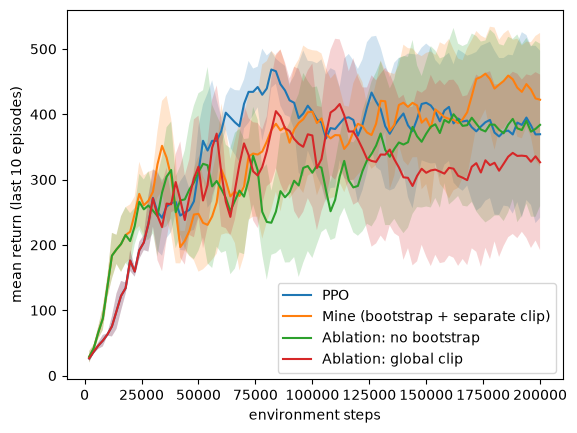

In [10]:
import functools

# bootstrap at truncation + separate gradient clipping for actor and critic
mine = {"bootstrap_trunc": True, "sep_clip": True}
my_runs = {"PPO": all_runs["PPO"],
           "Mine (bootstrap + separate clip)": run_seeds(train_fn=functools.partial(my_train_ppo, options={**mine, "tag": "mine"}))}
# ablations, remove one part at a time
my_runs["Ablation: no bootstrap"] = run_seeds(train_fn=functools.partial(my_train_ppo, options={**mine, "bootstrap_trunc": False, "tag": "no_boot"}))
my_runs["Ablation: global clip"] = run_seeds(train_fn=functools.partial(my_train_ppo, options={**mine, "sep_clip": False, "tag": "global_clip"}))
my_results = {name: summarize(runs, name) for name, runs in my_runs.items()}
plot_curves(my_runs)

**Check 1.** `my_train_ppo` with both parts turned off must give exactly the same training episodes as `train_ppo` (the PPO run of part (a)). This also records the logs of PPO in `LOGS`, which `train_ppo` does not do.

In [ ]:
# with both parts off, my_train_ppo must give exactly the same runs as train_ppo
off_runs = run_seeds(train_fn=functools.partial(my_train_ppo, options={"bootstrap_trunc": False, "sep_clip": False, "tag": "off"}), verbose=False)
print("same training episodes as train_ppo for all seeds:", all(a["episodes"] == b["episodes"] for a, b in zip(off_runs, my_runs["PPO"])))
summarize(off_runs, "my_train_ppo, both parts off")

**Check 2.** The diagnostics that `my_train_ppo` records in `LOGS` after every update, averaged over the 5 seeds in three parts of the training. These are the numbers behind my analysis. In the analysis I quote averages over 15 seeds (the 10 extra seeds are not run in this notebook), so some numbers differ a little from the ones printed here.

In [ ]:
import warnings; warnings.filterwarnings("ignore")
tags = {"off": "PPO (both off)", "global_clip": "bootstrap only", "no_boot": "separate clip only", "mine": "mine"}
windows = [(0, 70_000), (70_000, 140_000), (140_000, 200_001)]
keys = ["n_trunc", "adv_near_trunc", "adv_std", "v_loss", "actor_gn", "critic_gn", "kl", "clip_frac"]
print(f"{'version':<20}{'steps':>10}" + "".join(f"{k:>16}" for k in keys))
for tag, name in tags.items():
    for lo, hi in windows:
        row = [np.nanmean([np.nanmean([u[k] for u in LOGS[(tag, s)] if lo <= u["step"] < hi]) for s in SEEDS]) for k in keys]
        print(f"{name:<20}{lo // 1000:>4}-{hi // 1000:>3}k" + "".join(f"{x:>16.4f}" for x in row))
# n_trunc: truncated episodes per update (512 steps); adv_near_trunc: mean advantage of the last 20 steps before a truncation
# actor_gn / critic_gn: gradient norms before clipping; kl: approximate KL; clip_frac: fraction of ratios outside the clip range

### (iii) Results

I ran each version with the same 5 seeds (0 to 4), 200,000 steps and the same evaluation as in part (a), with the notebook's `run_seeds` and `summarize`. As a sanity check, `my_train_ppo` with both parts turned off gives exactly the same numbers as `train_ppo` for every seed (for example, the auc of seed 0 is 275.3 in both). Mean $\pm$ std over seeds:

| Version (5 seeds) | auc | steps_to_475 | runs reaching 475 | final (greedy) |
|---|---|---|---|---|
| PPO (default) | 341.6 $\pm$ 41.8 | 77,821 | 5/5 | 433.4 $\pm$ 89.3 |
| **Mine** (bootstrap $\pm$ separate clip) | 339.8 $\pm$ 42.5 | 101,417 | 4/5 | 454.6 $\pm$ 55.9 |
| Ablation: no bootstrap (separate clip only) | 304.1 $\pm$ 48.0 | 105,845 | 4/5 | 421.9 $\pm$ 125.7 |
| Ablation: global clip (bootstrap only) | 296.3 $\pm$ 45.7 | 84,828 | 5/5 | 393.1 $\pm$ 110.9 |

On these 5 seeds my method is not better than PPO: the auc is the same (339.8 vs 341.6) and it needs more steps to reach 475 (101k vs 78k, and one run never reaches it). The final greedy return is a bit higher (455 vs 433), but the std is about 50 to 90, so I don't think this is a real difference. The learning curves of the runs are in `my_runs` (the `plot_curves` call above).

Because the seed-to-seed std (about 45) is as big as the differences between the versions, 5 seeds were not enough for me to decide anything, so I ran 10 more seeds (5 to 14) for every version. These extra runs are only for my own check and are not part of the required 5-seed comparison:

| Version (15 seeds) | auc | steps_to_475 | runs reaching 475 | final (greedy) | paired auc difference to PPO (mean ± s.e.) | seeds better than PPO |
|---|---|---|---|---|---|---|
| PPO (default) | 315.2 $\pm$ 44.8 | 116,885 | 13/15 | 445.0 $\pm$ 92.7 | - | - |
| Mine (bootstrap + separate clip) | 337.2 $\pm$ 57.4 | 103,958 | 13/15 | 452.3 $\pm$ 83.6 | +22.0 $\pm$ 23.0 | 9/15 |
| No bootstrap (separate clip only) | 344.5 $\pm$ 54.7 | 93,446 | 13/15 | 468.3 ± 80.4 | +29.3 $\pm$ 18.8 | 9/15 |
| Global clip (bootstrap only) | 323.5 $\pm$ 53.8 | 108,404 | 13/15 | 446.4 $\pm$ 82.6 | +8.3 $\pm$ 19.9 | 8/15 |

With 15 seeds the results are different from the 5-seed ones: all three versions have a slightly higher auc than PPO, but none of the differences is bigger than about 1.5 standard errors.

### (iv) Ablation

I removed one part of the method at a time (the rows "no bootstrap" and "global clip" in the tables above; "no bootstrap" keeps the separate clipping, and "global clip" keeps the bootstrapping). Going to PPO is removing both.

* **5 seeds (auc):** PPO 341.6, mine 339.8, no bootstrap 304.1, global clip 296.3. Removing either part makes the auc decreaase by about 35 to 45, which looks like both parts are needed.
* **15 seeds (auc):** PPO 315.2, mine 337.2, no bootstrap 344.5, global clip 323.5. Now removing a part does not make things worse: the "no bootstrap" version is even a bit better than mine (344.5 vs 337.2, a difference much smaller than the std).

The ablation does not show that any single part is important. The conclusion from the 5 seeds was reversed by the extra seeds, so I think the 5-seed ablation differences were noise. An effect of 20 to 30 auc points with a std of about 50 per run would need many more than 15 seeds to measure.

### (v) Analysis

**Does my change improve learning.** No. On the required 5 seeds the auc is the same as PPO (339.8 vs 341.6) and it reaches 475 later. With 15 seeds the mean auc is higher for mine (337 vs 315), but the paired difference is 22 ± 23 (standard error), 9 out of 15 seeds are better, and the same is true for the ablated versions, so it is not significant. 

**Evidence that the bootstrap does what I expected.** The logs show that the mechanism works. For the last 20 steps before a truncation, the mean advantage in PPO is strongly negative (about -28 in steps 70k to 140k and -33 in 140k to 200k), while with bootstrapping it is slightly positive (+3.3 and +2.5). So the original code does punish the end of the successful episodes, and my fix removes this. The critic also fits better with the fix: the value loss in the last third of training is 34.6 (bootstrap only) and 32.0 (mine), against 44.8 for PPO, and the std of the advantages is 5.3 and 4.7, against 7.8. So the estimates were better, but the learning curves did not improve in a way I can measure.

**Reflect:** (1) Truncations are rare: only about 0.5 truncated episodes per update of 512 steps, so the 20 affected steps are only about 2% of the data in an update, and the other 98% of the samples are the same. (2) The policy changes very little in each update: the approximate KL is about 3e-4 and the clipping fraction is about 0.001, so the update is far from the clip range. This also fits what I saw in part (a), where removing the clipping changed little. (3) Andrychowicz et al. (2021) report that handling the step limit did not matter in their tasks either. The fix is correct in theory (it removes a bias), but the size of the bias effect on the policy is small here.

**Separate clipping did not help much.** The critic's gradient norm (about 20 to 30) is about 100 times bigger than the actor's (about 0.25), so the global clip scale is about 0.5/20 for the actor too. With separate clipping the actor is not clipped at all (0.25 < 0.5), and the clip fraction early in training is higher (0.0024 vs 0.0008), so the policy does move a little more. But the effect on the auc is not significant (+29 ± 19). I suspect Adam hides most of the scale difference, because it divides by the running size of the gradient.

**Why the first result looked bad, and what I learned.** With 5 seeds, bootstrapping alone looked worse (it was lower on all 5 seeds), and I could have written an explanation for that. Adding 10 seeds showed that it was noise: the difference became +8 $\pm$ 20. One reason is that after the first 500-step episode (around step 27k to 47k) a run with bootstrapping and a run without it use different random numbers, so the later behaviour of each seed is different, and the seeds are not "the same experiment" any more. Another reason is that PPO on CartPole has a large variance between seeds, and even the default PPO falls from 475 back to 200 in some seeds, as I showed in part (a).

**Limit:** I used 15 seeds for the extra check, one value of every hyperparameter, and I only tried a few variants, so I cannot say that the change never helps. The advantage mechanism was measured, but I did not measure whether the policy really changes less because of the wrong advantages. Whether the time limit is part of the task is an assumption; a time-aware agent (the other option in Pardo et al.) was not tested.

**Reference:**

- Fabio Pardo, Arash Tavakoli, Vitaly Levdik, Petar Kormushev. Time Limits in Reinforcement Learning. ICML 2018 (PMLR 80:4045-4054). arXiv:1712.00378.
- Shengyi Huang, Rousslan Fernand Julien Dossa, Antonin Raffin, Anssi Kanervisto, Weixun Wang. The 37 Implementation Details of Proximal Policy Optimization. ICLR Blog Track, 2022.
- Marcin Andrychowicz et al. What Matters in On-Policy Reinforcement Learning? A Large-Scale Empirical Study. arXiv:2006.05990 (ICLR 2021).